In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [6]:
df = pd.read_csv(r'D:\ML_Lab\housing_raw.csv')
df = df.drop_duplicates()
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

In [7]:

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [8]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regression': RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

In [10]:
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    results.append({
        'Model': name,
        'R2 Score': r2_score(y_test, predictions),
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions))
    })

    print(f"\n{name}")
    print(f"R2 Score: {r2_score(y_test, predictions):.4f}")
    print(f"MAE: {mean_absolute_error(y_test, predictions):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.2f}")
    if name == 'Linear Regression':
        lr_predictions = predictions
results_df = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))



Linear Regression
R2 Score: 0.3820
MAE: 65661.93
RMSE: 89728.70

Random Forest Regression
R2 Score: 0.8090
MAE: 32519.57
RMSE: 49881.64

MODEL COMPARISON
                   Model  R2 Score          MAE         RMSE
       Linear Regression  0.382019 65661.926358 89728.700342
Random Forest Regression  0.809017 32519.573355 49881.636930


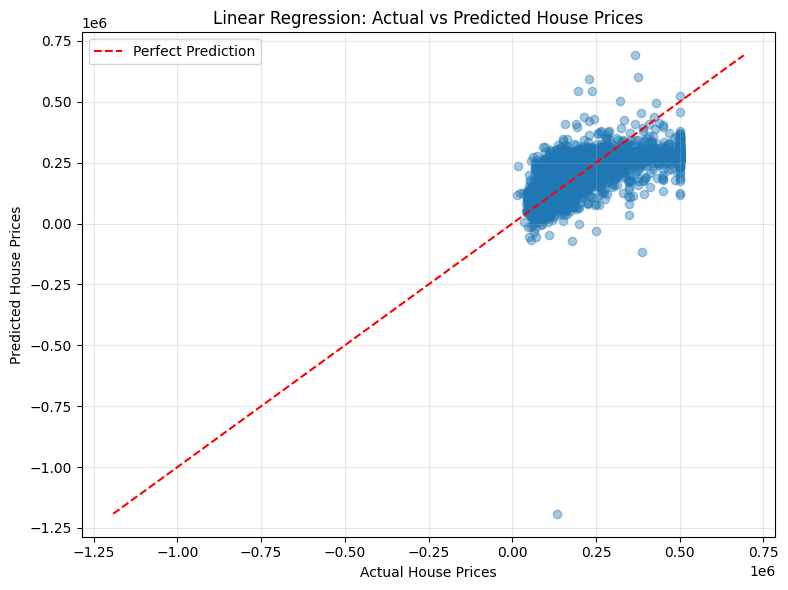

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, lr_predictions, alpha=0.4)

low = min(y_test.min(), lr_predictions.min())
high = max(y_test.max(), lr_predictions.max())

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Linear Regression: Actual vs Predicted House Prices')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
